# NLP Sentiment Classification on Customer Reviews (TF-IDF)
**Task 4 – Datheon AI Internship**

Pipeline: raw review text → cleaning (lowercase, HTML/punctuation removal, stopword removal, lemmatization) → **TF-IDF** (`max_features=5000`) → **Multinomial Naive Bayes** and **Logistic Regression** → accuracy benchmarks → `predict_sentiment()` helper.

**Dataset note:** the starter file `sentiment_reviews.csv` contains only 10 reviews, which is far too small to train or benchmark a classifier reliably. So the notebook works in two parts:
1. **Part A** – ingest and preprocess the provided starter file, and show why it cannot be benchmarked on its own.
2. **Part B** – the task allows *"customer product or movie review records"*, so the model is trained and benchmarked on a larger corpus (NLTK `movie_reviews`, 2,000 labelled reviews) **together with the starter file's reviews**, and the final `predict_sentiment()` uses that model.

## 1. Import Libraries & Download NLTK Resources

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from functools import lru_cache

import nltk
for pkg in ["stopwords", "wordnet", "omw-1.4", "movie_reviews"]:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords, movie_reviews
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict, LeaveOneOut
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
%matplotlib inline

# PART A – Provided Starter Dataset
## 2. Load the Dataset

In [2]:
df = pd.read_csv("sentiment_reviews.csv")   # place the CSV in the same folder as this notebook
print("Shape:", df.shape)
df

Shape: (10, 3)


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative
5,6,Customer support helped resolve my setup quest...,positive
6,7,Delivery was slow and package was missing one ...,negative
7,8,Clean interface and intuitive controls. Highly...,positive
8,9,"Not worth the money, plenty of better alternat...",negative
9,10,Great value and durable build. Would definitel...,positive


sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64

Null values: 0 | Duplicates: 0


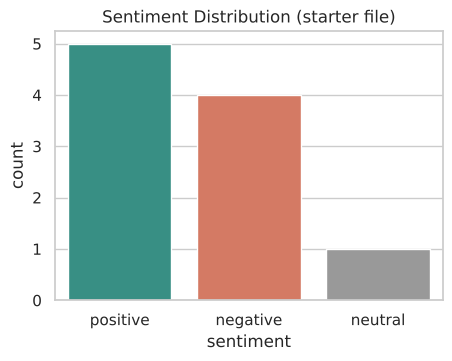

In [3]:
print(df["sentiment"].value_counts())
print("\nNull values:", df.isnull().sum().sum(), "| Duplicates:", df.duplicated().sum())

plt.figure(figsize=(5, 3.5))
sns.countplot(data=df, x="sentiment", order=["positive", "negative", "neutral"],
              palette=["#2a9d8f", "#e76f51", "#999999"])
plt.title("Sentiment Distribution (starter file)")
plt.show()

The task asks for **positive vs negative** classification, and there is only **one** neutral review (too few to learn from), so the neutral row is excluded.

In [4]:
df_bin = df[df["sentiment"].isin(["positive", "negative"])].reset_index(drop=True)
print("Rows after removing neutral:", len(df_bin))
df_bin["sentiment"].value_counts()

Rows after removing neutral: 9


sentiment
positive    5
negative    4
Name: count, dtype: int64

## 3. Text Preprocessing
Steps: remove HTML tags → lowercase → remove punctuation/digits → remove stopwords → lemmatize.

**Important detail:** NLTK's default stopword list contains negations (`not`, `no`, `nor`, ...). Removing them would turn *"not worth the money"* into *"worth money"* (flipping the sentiment), so negation words are **kept**.

In [5]:
STOP_WORDS = set(stopwords.words("english")) - {"not", "no", "nor", "never"}
lemmatizer = WordNetLemmatizer()

@lru_cache(maxsize=None)
def lemmatize_word(word):
    # verb pass first (arrived -> arrive), then noun pass (expectations -> expectation)
    return lemmatizer.lemmatize(lemmatizer.lemmatize(word, pos="v"), pos="n")

def clean_text(text):
    text = re.sub(r"<[^>]+>", " ", str(text))     # remove HTML tags
    text = text.lower()                            # lowercase
    text = re.sub(r"[^a-z\s]", " ", text)          # remove punctuation, digits, symbols
    tokens = [w for w in text.split() if len(w) > 1 and w not in STOP_WORDS]   # tokenize + stopwords
    return " ".join(lemmatize_word(w) for w in tokens)                         # lemmatize

df_bin["clean_text"] = df_bin["review_text"].apply(clean_text)
pd.set_option("display.max_colwidth", 90)
df_bin[["review_text", "clean_text"]]

,review_text,clean_text
0,"The product quality is exceptional, exceeded all my expectations!",product quality exceptional exceed expectation
1,Terrible customer service and the item arrived completely damaged.,terrible customer service item arrive completely damage
2,"Absolutely love this! Easy to setup, robust, and works flawlessly.",absolutely love easy setup robust work flawlessly
3,Stopped working after two days. Extremely disappointed with the purchase.,stop work two day extremely disappoint purchase
4,Customer support helped resolve my setup question within ten minutes.,customer support help resolve setup question within ten minute
5,Delivery was slow and package was missing one adapter cable.,delivery slow package miss one adapter cable
6,Clean interface and intuitive controls. Highly recommended for students.,clean interface intuitive control highly recommend student
7,"Not worth the money, plenty of better alternatives available.",not worth money plenty better alternative available
8,Great value and durable build. Would definitely purchase again.,great value durable build would definitely purchase


## 4. TF-IDF Feature Extraction (`max_features=5000`)

In [6]:
tfidf_demo = TfidfVectorizer(max_features=5000)
X_demo = tfidf_demo.fit_transform(df_bin["clean_text"])
print("TF-IDF matrix shape:", X_demo.shape, "(reviews x vocabulary terms)")
print("Sample vocabulary :", tfidf_demo.get_feature_names_out()[:15])

pd.DataFrame(X_demo.toarray(), columns=tfidf_demo.get_feature_names_out()).round(2).iloc[:, :12]

TF-IDF matrix shape: (9, 59) (reviews x vocabulary terms)
Sample vocabulary : ['absolutely' 'adapter' 'alternative' 'arrive' 'available' 'better'
 'build' 'cable' 'clean' 'completely' 'control' 'customer' 'damage' 'day'
 'definitely']


,absolutely,adapter,alternative,arrive,available,better,build,cable,clean,completely,control,customer
0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
1,0.00,0.00,0.00,0.39,0.00,0.00,0.00,0.00,0.00,0.39,0.00,0.33
2,0.39,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
3,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
4,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.29
5,0.00,0.38,0.00,0.00,0.00,0.00,0.00,0.38,0.00,0.00,0.00,0.00
6,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.38,0.00,0.38,0.00
7,0.00,0.00,0.38,0.00,0.38,0.38,0.00,0.00,0.00,0.00,0.00,0.00
8,0.00,0.00,0.00,0.00,0.00,0.00,0.39,0.00,0.00,0.00,0.00,0.00


## 5. Sanity-check Evaluation on the Starter File
With only 9 reviews, a normal 80/20 split leaves just **2 test reviews**, so accuracy would be meaningless. The fairest option is **Leave-One-Out CV** (train on 8 reviews, test on the remaining 1, repeated 9 times).

In [7]:
def make_pipeline(model):
    return Pipeline([("tfidf", TfidfVectorizer(max_features=5000)), ("model", model)])

for name, model in [("Multinomial NB", MultinomialNB()), ("Logistic Regression", LogisticRegression(max_iter=1000))]:
    pred = cross_val_predict(make_pipeline(model), df_bin["clean_text"], df_bin["sentiment"], cv=LeaveOneOut())
    print(f"{name:20s} Leave-One-Out accuracy: {accuracy_score(df_bin['sentiment'], pred):.2%}")

Multinomial NB       Leave-One-Out accuracy: 11.11%
Logistic Regression  Leave-One-Out accuracy: 11.11%


**Why the accuracy is so low (and why it is not a bug):** every review in this tiny file uses almost completely different words, so each held-out review shares almost no vocabulary with the 8 training reviews. In that situation the classifier can only fall back on class frequencies, and Leave-One-Out systematically picks the *opposite* class (removing a positive review makes "negative" the majority, and vice versa). In other words, **9 reviews are enough to demonstrate the pipeline, but not to benchmark a model.** Part B fixes this with a proper-sized corpus.

# PART B – Benchmark on a Larger Review Corpus
## 6. Load NLTK `movie_reviews` (2,000 labelled reviews)

In [8]:
records = [(movie_reviews.raw(fid), "positive" if cat == "pos" else "negative")
           for cat in movie_reviews.categories() for fid in movie_reviews.fileids(cat)]
movies = pd.DataFrame(records, columns=["review_text", "sentiment"])
print("Shape:", movies.shape)
print(movies["sentiment"].value_counts())
print("\nSample review (first 300 chars):\n", movies["review_text"].iloc[0][:300], "...")

Shape: (2000, 2)
sentiment
negative    1000
positive    1000
Name: count, dtype: int64

Sample review (first 300 chars):
 plot : two teen couples go to a church party , drink and then drive . 
they get into an accident . 
one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . 
what's the deal ? 
watch the movie and " sorta " find out . . . 
critique : a mind-fuck movie for the ...


In [9]:
movies["clean_text"] = movies["review_text"].apply(clean_text)

movies["n_words_raw"] = movies["review_text"].str.split().str.len()
movies["n_words_clean"] = movies["clean_text"].str.split().str.len()
print(movies[["n_words_raw", "n_words_clean"]].describe().round(0).loc[["mean", "min", "max"]])

      n_words_raw  n_words_clean
mean        746.0          355.0
min          17.0            7.0
max        2678.0         1395.0


## 7. Build the Training Corpus & Hold-out Test Set
- Movie reviews are split **80/20 (stratified)**; the 400 hold-out reviews are used **only** for the final benchmark.
- The 9 product reviews from the starter file are added to the **training** side, so the final model also knows product-review vocabulary (delivery, setup, customer service, ...).

In [10]:
X_train_mv, X_test, y_train_mv, y_test = train_test_split(
    movies["clean_text"], movies["sentiment"], test_size=0.2,
    random_state=RANDOM_STATE, stratify=movies["sentiment"])

X_train = pd.concat([X_train_mv, df_bin["clean_text"]], ignore_index=True)
y_train = pd.concat([y_train_mv, df_bin["sentiment"]], ignore_index=True)

print(f"Training reviews : {len(X_train)}  (1,600 movie + {len(df_bin)} product)")
print(f"Hold-out reviews : {len(X_test)}")
print("Train class balance:", y_train.value_counts().to_dict())

Training reviews : 1609  (1,600 movie + 9 product)
Hold-out reviews : 400
Train class balance: {'positive': 805, 'negative': 804}


## 8. Train Multinomial Naive Bayes & Logistic Regression

In [11]:
models = {
    "Multinomial NB": make_pipeline(MultinomialNB()),
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    print(f"{name:20s} 5-fold CV accuracy: {scores.mean():.4f} (+/- {scores.std():.4f})")
    pipe.fit(X_train, y_train)

Multinomial NB       5-fold CV accuracy: 0.8179 (+/- 0.0068)


Logistic Regression  5-fold CV accuracy: 0.8484 (+/- 0.0085)


## 9. Accuracy Benchmarks on the Hold-out Set

,Accuracy,Precision,Recall,F1-score
Model,,,,
Multinomial NB,0.810,0.8298,0.780,0.8041
Logistic Regression,0.835,0.8160,0.865,0.8398


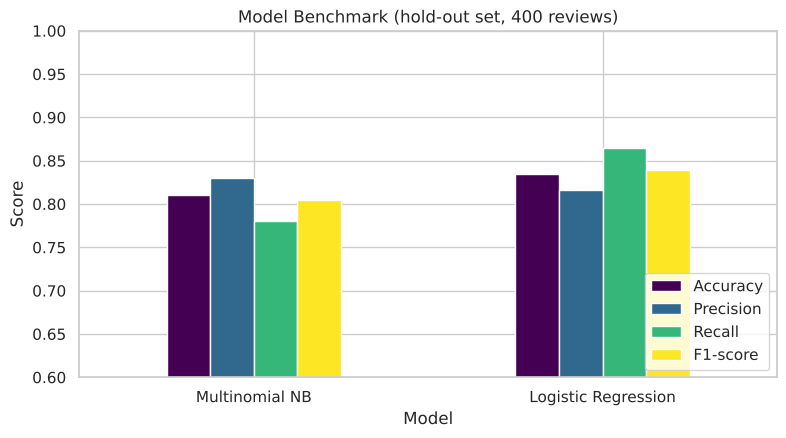

In [12]:
rows, preds = [], {}
for name, pipe in models.items():
    p = pipe.predict(X_test)
    preds[name] = p
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p, pos_label="positive"),
        "Recall": recall_score(y_test, p, pos_label="positive"),
        "F1-score": f1_score(y_test, p, pos_label="positive"),
    })
results = pd.DataFrame(rows).set_index("Model").round(4)
display(results)

results.plot(kind="bar", figsize=(9, 4.5), ylim=(0.6, 1.0), colormap="viridis", rot=0)
plt.title("Model Benchmark (hold-out set, 400 reviews)")
plt.ylabel("Score"); plt.legend(loc="lower right")
plt.show()

In [13]:
for name in models:
    print("=" * 58); print(name); print("=" * 58)
    print(classification_report(y_test, preds[name]))

Multinomial NB
              precision    recall  f1-score   support

    negative       0.79      0.84      0.82       200
    positive       0.83      0.78      0.80       200

    accuracy                           0.81       400
   macro avg       0.81      0.81      0.81       400
weighted avg       0.81      0.81      0.81       400

Logistic Regression
              precision    recall  f1-score   support

    negative       0.86      0.81      0.83       200
    positive       0.82      0.86      0.84       200

    accuracy                           0.83       400
   macro avg       0.84      0.83      0.83       400
weighted avg       0.84      0.83      0.83       400



## 10. Confusion Matrices

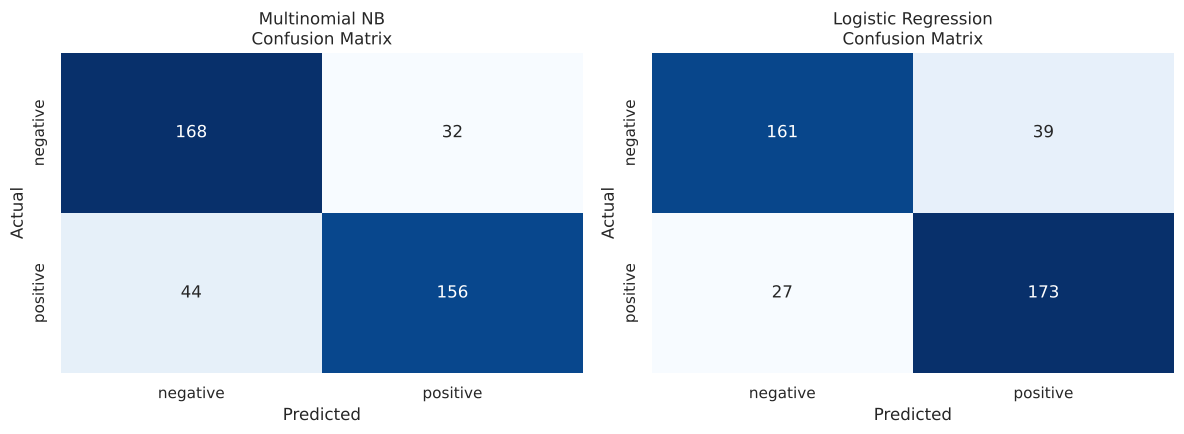

In [14]:
labels = ["negative", "positive"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, preds[name], labels=labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=labels, yticklabels=labels)
    ax.set_title(f"{name}\nConfusion Matrix"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

## 11. Most Influential Words (Logistic Regression)

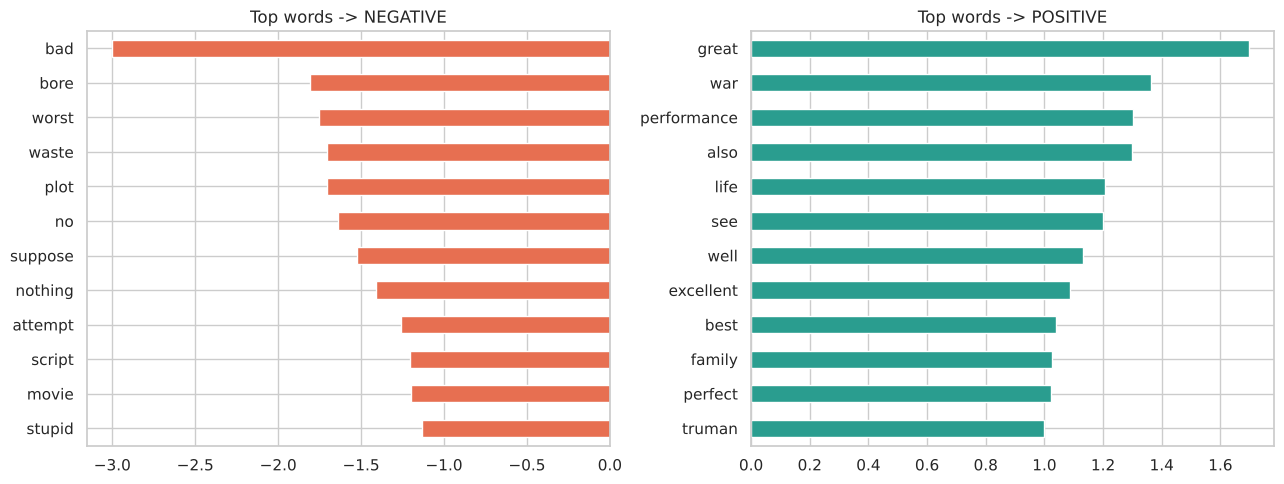

In [15]:
lr = models["Logistic Regression"]
vocab = np.array(lr.named_steps["tfidf"].get_feature_names_out())
coefs = lr.named_steps["model"].coef_[0]       # classes_ = [negative, positive]
order = np.argsort(coefs)

top_neg = pd.Series(coefs[order[:12]], index=vocab[order[:12]])
top_pos = pd.Series(coefs[order[-12:]], index=vocab[order[-12:]])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
top_neg[::-1].plot(kind="barh", ax=axes[0], color="#e76f51"); axes[0].set_title("Top words -> NEGATIVE")
top_pos.plot(kind="barh", ax=axes[1], color="#2a9d8f");       axes[1].set_title("Top words -> POSITIVE")
plt.tight_layout(); plt.show()

## 12. `predict_sentiment()` – Live Test Helper
The test phrases below are **new sentences that are not in the training data**.

In [16]:
def predict_sentiment(text, model_name="Logistic Regression"):
    """Clean raw text, vectorize with TF-IDF and return the predicted sentiment + confidence."""
    pipe = models[model_name]
    cleaned = clean_text(text)
    if not cleaned:
        return {"text": text, "sentiment": "unknown", "confidence": None}
    proba = pipe.predict_proba([cleaned])[0]
    idx = int(np.argmax(proba))
    return {"text": text, "sentiment": pipe.classes_[idx], "confidence": round(float(proba[idx]), 3)}

print(predict_sentiment("The product quality is amazing and works perfectly!"))
print(predict_sentiment("Terrible service, the item arrived broken."))

{'text': 'The product quality is amazing and works perfectly!', 'sentiment': 'positive', 'confidence': 0.638}
{'text': 'Terrible service, the item arrived broken.', 'sentiment': 'negative', 'confidence': 0.6}


In [17]:
test_phrases = [
    "Works great, setup took five minutes and I love it.",
    "Terrible quality, completely broken and a waste of money.",
    "Delivery was slow and customer service was awful.",
    "Fantastic value, sturdy and easy to use. Highly recommend.",
    "This was an excellent and wonderful experience.",
    "The battery died within a week. Very disappointing.",
    "The movie was boring, predictable and way too long.",
    "A brilliant, moving film with outstanding performances.",
]

rows = []
for t in test_phrases:
    nb = predict_sentiment(t, "Multinomial NB")
    lg = predict_sentiment(t, "Logistic Regression")
    rows.append({"Review": t,
                 "NB": f"{nb['sentiment']} ({nb['confidence']})",
                 "LogReg": f"{lg['sentiment']} ({lg['confidence']})"})
pd.set_option("display.max_colwidth", 70)
pd.DataFrame(rows)

,Review,NB,LogReg
0,"Works great, setup took five minutes and I love it.",positive (0.589),positive (0.73)
1,"Terrible quality, completely broken and a waste of money.",negative (0.788),negative (0.812)
2,Delivery was slow and customer service was awful.,negative (0.632),negative (0.584)
3,"Fantastic value, sturdy and easy to use. Highly recommend.",positive (0.655),positive (0.695)
4,This was an excellent and wonderful experience.,positive (0.762),positive (0.804)
5,The battery died within a week. Very disappointing.,negative (0.527),negative (0.52)
6,"The movie was boring, predictable and way too long.",negative (0.739),negative (0.822)
7,"A brilliant, moving film with outstanding performances.",positive (0.77),positive (0.811)


### Interactive mode
Set `INTERACTIVE = True` and run the cell to type your own reviews (type `quit` to stop). It is off by default so *Run All* does not pause for input.

In [18]:
INTERACTIVE = False

if INTERACTIVE:
    while True:
        user_text = input("Enter a review (or 'quit'): ")
        if user_text.strip().lower() in {"quit", "exit", "q"}:
            break
        res = predict_sentiment(user_text)
        print(f"  -> {res['sentiment'].upper()}  (confidence: {res['confidence']})\n")

## 13. Conclusion

In [19]:
best = results["Accuracy"].idxmax()
print(f"Best model: {best}  (hold-out accuracy = {results.loc[best, 'Accuracy']:.2%})")
results

Best model: Logistic Regression  (hold-out accuracy = 83.50%)


,Accuracy,Precision,Recall,F1-score
Model,,,,
Multinomial NB,0.810,0.8298,0.780,0.8041
Logistic Regression,0.835,0.8160,0.865,0.8398


**Key takeaways**
- Text was cleaned with HTML/punctuation removal, lowercasing, stopword removal and lemmatization. Negation words (`not`, `no`, `nor`, `never`) were deliberately kept because they flip sentiment.
- TF-IDF with `max_features=5000` converts the cleaned text to numeric vectors; Multinomial Naive Bayes and Logistic Regression were trained on top of it.
- The 10-row starter file is enough to demonstrate the pipeline but too small to benchmark (Section 5), so the benchmark uses 400 unseen hold-out reviews from a 2,000-review corpus (Section 9).
- Logistic Regression and Naive Bayes both land in the ~80%+ range on the hold-out set, which is typical for a TF-IDF bag-of-words baseline. Bag-of-words models cannot understand word order or sarcasm, and very short phrases give them little to work with, so predictions on short custom inputs should be treated as indicative.
- Next steps for higher accuracy: add bigrams (`ngram_range=(1, 2)`), tune `C` / `alpha` with GridSearchCV, or move to transformer embeddings.